# Slide-tags tonsil (Fig. S9): analysis of the 10,000-HVG panel

1. Naive vs memory B cells: KMeans (k = 2) confusion matrices (Fig. S9D)
2. Naive vs memory B cells: canonical markers (Fig. S9E), DE recall and precision against the annotation-derived markers (Fig. S9F)
3. Plasma cells, germinal center vs mantle zone: UMAPs (Fig. S9G-H)

Run `slidetags_build.ipynb` and `tonsil/run_panel.sh 10000hvg` first (see the README).
Figures go to `slidetags_tonsil/figures/tonsil_10000hvg/` (svg and png).

In [1]:
import os

import colorcet as cc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

plt.rcParams["svg.fonttype"] = "none"  # keep text as text in SVGs
sc.settings._vector_friendly = True
sc.set_figure_params(dpi=150, fontsize=12, format="svg")

PANEL = os.environ.get("PANEL", "10000hvg")  # this notebook is the 10k-HVG panel; the env var only overrides it
STEM = f"tonsil_nl_{PANEL}"
FIGURES_FOLDER = os.path.join(
    f"/home/nathanl/scviva_paper/slidetags_tonsil/figures/tonsil_{PANEL}", os.environ.get("FIGURES_SUBDIR", "")
)
os.makedirs(FIGURES_FOLDER, exist_ok=True)
print("PANEL =", PANEL, "| figures ->", FIGURES_FOLDER)


def save(name):
    for ext in ("svg", "png"):
        plt.savefig(os.path.join(FIGURES_FOLDER, f"{name}.{ext}"), bbox_inches="tight", dpi=500)

PANEL = 10000hvg | figures -> /home/nathanl/scviva_paper/slidetags_tonsil/figures/tonsil_10000hvg/


## Load the embeddings for this panel

In [2]:
CKPT = "/home/nathanl/scviva_paper/slidetags_tonsil/checkpoints"

# supervised run: X_scanvi + scVIVA, and the BANKSY/SimVI embeddings it inherited from the data file
adata = sc.read_h5ad(f"{CKPT}/tonsil_{PANEL}/{STEM}/{STEM}_nicheVI.h5ad")

# unlabeled run: scVI (its Leiden clusters are the pseudo-labels) + unlabeled scVIVA
_nl = sc.read_h5ad(os.environ.get("NL_H5AD", f"{CKPT}/tonsil_nolabels/{STEM}/{STEM}_nicheVI.h5ad"))
assert _nl.obs_names.equals(adata.obs_names)
_nl_key = [k for k in _nl.obsm if k.endswith("_s10_scvi_lr0.0005_poisson_X_nicheVI")]
assert len(_nl_key) == 1, _nl_key
adata.obsm["X_scVI"] = _nl.obsm["X_scVI"]
adata.obsm["scviva_unlabeled"] = _nl.obsm[_nl_key[0]]
print("unlabeled scVIVA:", _nl_key[0], "| pseudo-labels:", [c for c in _nl.obs if c.startswith("leiden_scvi_res")])
del _nl

# scANVI is included as the supervised expression-only reference. It is semi-supervised on
# cell_type, so its scores in the B_naive/B_memory analyses are partly circular;
# it never saw `region`, so the plasma GC-vs-mantle comparison is fair for it. Harmony is left out: single donor, so it is a copy of BANKSY.
full_embeddings = {
    "BANKSY (lambda 0.2)": "banksy_pc_20_lambda_0.2",
    "SimVI": "simvi25_both_mae_50",
    "scVI": "X_scVI",
    "scANVI": "X_scanvi",
    "scVIVA": "s10_scanvi_lr0.0005_poisson_X_nicheVI",
    "scVIVA (unlabeled)": "scviva_unlabeled",
}
for k in full_embeddings.values():
    assert k in adata.obsm, k
print(adata)

unlabeled scVIVA: 0.15_s10_scvi_lr0.0005_poisson_X_nicheVI | pseudo-labels: ['leiden_scvi_res0.15']
AnnData object with n_obs × n_vars = 5778 × 10000
    obs: 'cell_type', 'biosample_id', 'donor_id', 'species', 'disease', 'organ', 'library_preparation_protocol', 'sex', 'dataset', 'sample_id', 'tissue', 'total_counts', 'n_genes', 'region', '_scvi_batch', '_scvi_labels', 'index', '_scvi_sample', 's10_scanvi_lr0.0005_poisson_compo_error', 's10_scanvi_lr0.0005_poisson_niche_error'
    var: 'gene_id', 'feature_type', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mt'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'cell_type_colors', 'hvg', 'log1p', 'neighbors', 'umap'
    obsm: 'X_banksy_02_harmony', 'X_scanvi', 'X_umap', 'banksy_pc_20_lambda_0.2', 'banksy_pc_20_nonspatial', 'neighborhood_composition', 'niche_distances', 'niche_indexes', 'qz1_m', 'qz1_m_niche_ct', 's10_scanvi_lr0.0005_poisson_X_nicheVI', 'simvi25_all_mae_50', 'simvi25_both_mae_5

## 1. B_naive vs B_memory: KMeans (k = 2) confusion matrices

region,T_zone,germinal_center,mantle_zone,total
cell_type,,,,
B_naive,243,64,760,1067
B_memory,174,38,304,516
plasma,26,187,49,262


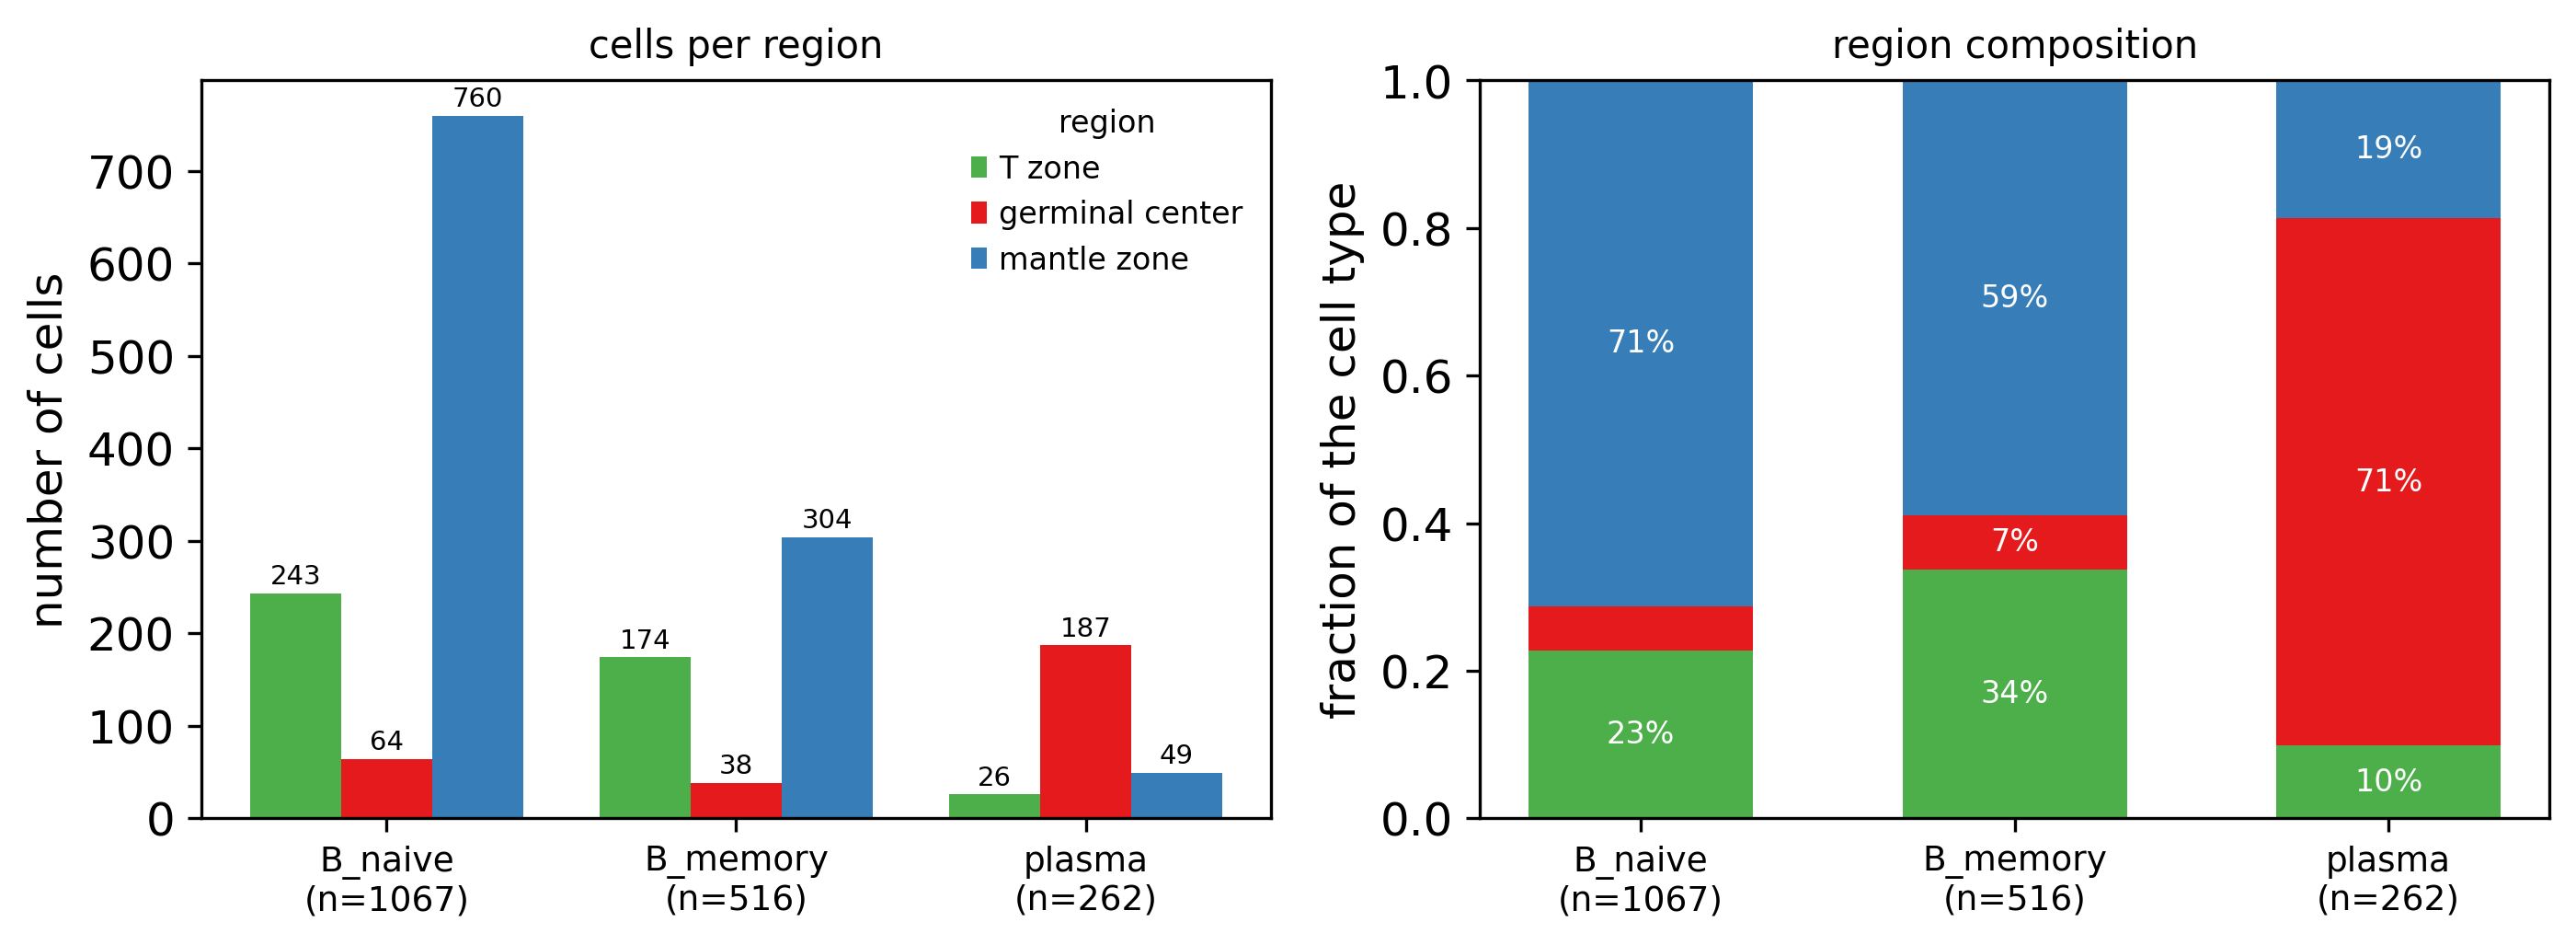

In [4]:
# Where do the cell types of the two case studies sit? Counts (left) and fractions (right) of B_naive,
# B_memory and plasma cells per region. This motivates the two contrasts used below: naive/memory B cells
# are mostly mantle-zone with a T-zone minority (-> mantle vs non-mantle), plasma cells are mostly
# germinal-center with a mantle-zone minority (-> germinal center vs mantle zone).
LAYOUT_TYPES = ["B_naive", "B_memory", "plasma"]
LAYOUT_REGIONS = ["T_zone", "germinal_center", "mantle_zone"]
LAYOUT_COLORS = {"T_zone": "#4daf4a", "germinal_center": "#e41a1c", "mantle_zone": "#377eb8"}
_obs = adata.obs[adata.obs["cell_type"].isin(LAYOUT_TYPES)]
layout_counts = pd.crosstab(_obs["cell_type"].astype(str), _obs["region"].astype(str)).reindex(
    index=LAYOUT_TYPES, columns=LAYOUT_REGIONS).fillna(0).astype(int)
layout_frac = layout_counts.div(layout_counts.sum(1), axis=0)
display(layout_counts.assign(total=layout_counts.sum(1)))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
_x = np.arange(len(LAYOUT_TYPES))
_w = 0.26
for k, r in enumerate(LAYOUT_REGIONS):  # left: counts, grouped
    b = axes[0].bar(_x + (k - 1) * _w, layout_counts[r], _w, color=LAYOUT_COLORS[r], label=r.replace("_", " "))
    axes[0].bar_label(b, fontsize=7, padding=1)
axes[0].set_ylabel("number of cells")
axes[0].set_title("cells per region", fontsize=10)
bottom = np.zeros(len(LAYOUT_TYPES))
for r in LAYOUT_REGIONS:  # right: fractions, stacked
    axes[1].bar(_x, layout_frac[r], 0.6, bottom=bottom, color=LAYOUT_COLORS[r])
    for i, v in enumerate(layout_frac[r]):
        if v >= 0.06:
            axes[1].text(i, bottom[i] + v / 2, f"{100 * v:.0f}%", ha="center", va="center", fontsize=8, color="white")
    bottom += layout_frac[r].values
axes[1].set_ylabel("fraction of the cell type")
axes[1].set_ylim(0, 1)
axes[1].set_title("region composition", fontsize=10)
for ax in axes:
    ax.set_xticks(_x)
    ax.set_xticklabels([f"{t}\n(n={n})" for t, n in zip(LAYOUT_TYPES, layout_counts.sum(1))], fontsize=9)
    ax.grid(False)
axes[0].legend(fontsize=8, frameon=False, title="region", title_fontsize=8)
plt.tight_layout()
save(f"tonsil_{PANEL}_celltype_region_layout")

n=1583  majority-class baseline = 0.674
region balanced accuracy of the true naive/memory split = 0.561
BANKSY (lambda 0.2): accuracy = 0.551 | balanced accuracy = 0.537 | region balanced accuracy = 0.850 | ARI = 0.009 | NMI = 0.004
SimVI: accuracy = 0.615 | balanced accuracy = 0.595 | region balanced accuracy = 0.829 | ARI = 0.049 | NMI = 0.025
scVI: accuracy = 0.649 | balanced accuracy = 0.675 | region balanced accuracy = 0.547 | ARI = 0.089 | NMI = 0.084
scANVI: accuracy = 0.924 | balanced accuracy = 0.928 | region balanced accuracy = 0.562 | ARI = 0.715 | NMI = 0.600
scVIVA: accuracy = 0.946 | balanced accuracy = 0.945 | region balanced accuracy = 0.572 | ARI = 0.792 | NMI = 0.678
scVIVA (unlabeled): accuracy = 0.689 | balanced accuracy = 0.667 | region balanced accuracy = 0.665 | ARI = 0.136 | NMI = 0.080


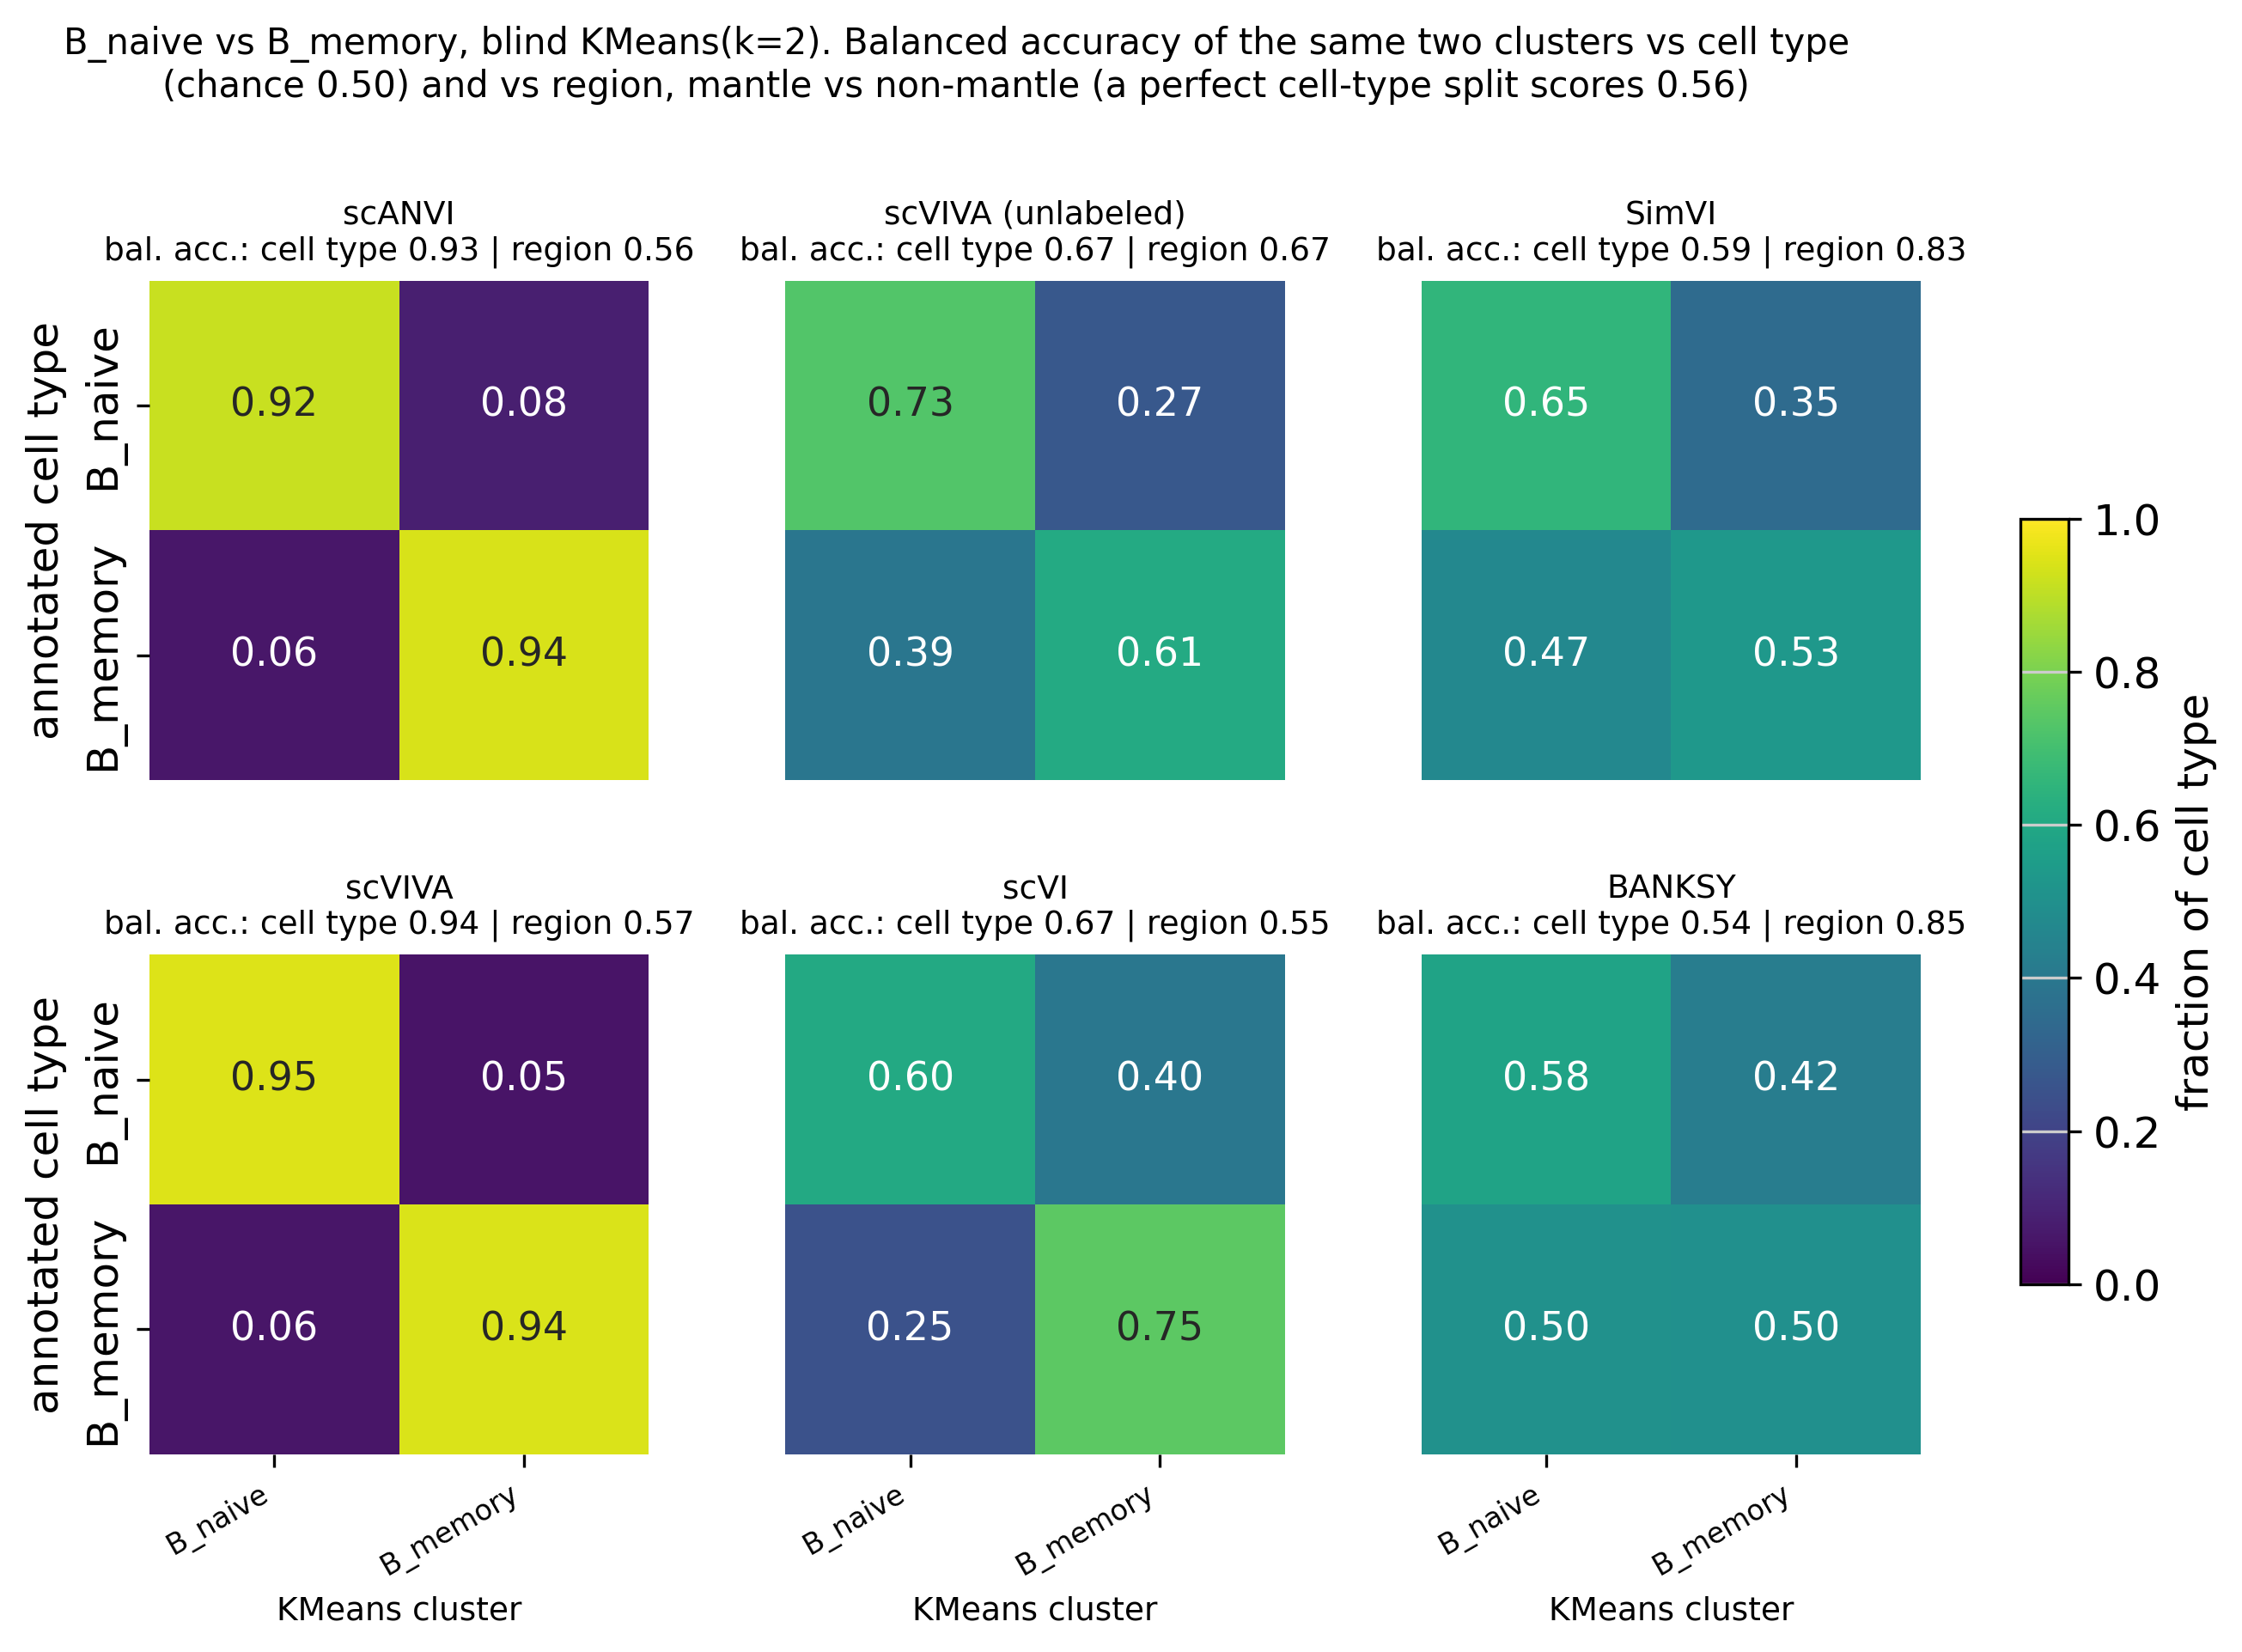

In [5]:
B_PAIR = ["B_naive", "B_memory"]

sub_b = adata[adata.obs["cell_type"].isin(B_PAIR)].copy()
sub_b.obs["cell_type"] = pd.Categorical(sub_b.obs["cell_type"].astype(str), categories=B_PAIR, ordered=True)
truth_b = sub_b.obs["cell_type"].values
baseline_b = pd.Series(truth_b).value_counts(normalize=True).max()
print(f"n={sub_b.n_obs}  majority-class baseline = {baseline_b:.3f}")

# region, two-class: mantle zone vs the rest (T zone + germinal center; only 102 B cells sit in the GC).
# A perfect naive/memory split scores ~0.56 on it (naive cells are a bit more often in the mantle), so
# that -- not 0.5 -- is the value of a split that carries no location information beyond cell type.
region2_b = np.where(sub_b.obs["region"].astype(str).values == "mantle_zone", "mantle", "non-mantle")


def _balanced_acc(truth, cl):
    """Hungarian-match the clusters to the classes of `truth`, then mean per-class recall."""
    cm = pd.crosstab(truth, cl)
    r, c = linear_sum_assignment(-cm.values)
    mp = {cm.columns[j]: cm.index[i] for i, j in zip(r, c)}
    pred = np.array([mp[v] for v in cl])
    return float(np.mean([(pred[truth == g] == g).mean() for g in np.unique(truth)]))


REGION_REF_B = _balanced_acc(region2_b, np.asarray(truth_b).astype(str))  # the true naive/memory split
print(f"region balanced accuracy of the true naive/memory split = {REGION_REF_B:.3f}")

conf_b, scores_b = {}, {}
for label, key in full_embeddings.items():
    cl = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(sub_b.obsm[key])
    sub_b.obs[f"km2_{label}"] = cl.astype(str)

    cmtx = sc.metrics.confusion_matrix("cell_type", f"km2_{label}", sub_b.obs)
    _, col_ind = linear_sum_assignment(-cmtx.values)
    cmtx = cmtx.iloc[:, col_ind]
    cmtx.columns = B_PAIR  # each aligned cluster labelled by the cell type it matches
    conf_b[label] = cmtx

    counts = pd.crosstab(truth_b, cl).values
    r, c = linear_sum_assignment(-counts)
    scores_b[label] = {
        "accuracy": counts[r, c].sum() / counts.sum(),
        "ARI": adjusted_rand_score(truth_b, cl),
        "NMI": normalized_mutual_info_score(truth_b, cl),
        # mean per-class recall = mean of the diagonal of the row-normalised, Hungarian-aligned matrix
        "balanced_accuracy": float(np.mean(np.diag(cmtx.values))),
        "region_balanced_accuracy": _balanced_acc(region2_b, cl),
    }
    s = scores_b[label]
    print(f"{label}: accuracy = {s['accuracy']:.3f} | balanced accuracy = {s['balanced_accuracy']:.3f} | "
          f"region balanced accuracy = {s['region_balanced_accuracy']:.3f} | ARI = {s['ARI']:.3f} | NMI = {s['NMI']:.3f}")

# 2 x 3 grid, by column: label-trained (scANVI, scVIVA) | unsupervised (scVIVA unlabeled, scVI) | spatial (SimVI, BANKSY)
K2_LAYOUT = [
    ["scANVI", "scVIVA (unlabeled)", "SimVI"],
    ["scVIVA", "scVI", "BANKSY (lambda 0.2)"],
]
assert sorted(sum(K2_LAYOUT, [])) == sorted(conf_b), "K2_LAYOUT must list every method exactly once"
_nrow, _ncol = len(K2_LAYOUT), len(K2_LAYOUT[0])
fig, axes = plt.subplots(_nrow, _ncol, figsize=(3.4 * _ncol, 3.3 * _nrow))
for r_, row in enumerate(K2_LAYOUT):
    for c_, label in enumerate(row):
        ax, cmtx = axes[r_, c_], conf_b[label]
        _is_bottom, _is_left = r_ == _nrow - 1, c_ == 0
        sns.heatmap(
            cmtx,
            ax=ax,
            cmap="viridis",
            vmin=0,
            vmax=1,
            square=True,
            cbar=False,
            annot=True,
            fmt=".2f",
            annot_kws={"size": 11},
            xticklabels=(B_PAIR if _is_bottom else False),
            yticklabels=(B_PAIR if _is_left else False),
            linewidths=0,
        )
        ax.grid(False)
        s_ = scores_b[label]
        ax.set_title(f"{label.replace(' (lambda 0.2)', '')}\nbal. acc.: cell type {s_['balanced_accuracy']:.2f} | "
                     f"region {s_['region_balanced_accuracy']:.2f}", fontsize=9)
        ax.set_xlabel("KMeans cluster" if _is_bottom else "", fontsize=9)
        ax.set_ylabel("annotated cell type" if _is_left else "")
        if _is_bottom:
            plt.setp(ax.get_xticklabels(), rotation=30, ha="right", fontsize=8)
fig.suptitle("B_naive vs B_memory, blind KMeans(k=2). Balanced accuracy of the same two clusters vs cell type\n"
             f"(chance 0.50) and vs region, mantle vs non-mantle (a perfect cell-type split scores {REGION_REF_B:.2f})",
             fontsize=10, y=0.99)
fig.subplots_adjust(right=0.88, hspace=0.35, wspace=0.12, top=0.84)
cax = fig.add_axes([0.905, 0.25, 0.018, 0.45])
fig.colorbar(axes[0, 0].collections[0], cax=cax, label="fraction of cell type")
save(f"tonsil_{PANEL}_bcell_confusion_k2")

## 2. B_naive vs B_memory: canonical markers, DE recall and precision

Reference set = DE between the published B_naive / B_memory annotations (no clustering), on full
genes. For each method: blind KMeans(k=2) on its embedding, then DE between the two clusters,
scored as recall (how many reference markers it finds) and precision (how much of what it finds is
on-target). The reference comes from the annotations, so recall is not circular; precision is the
softer number, since "off-target" genes could be real biology the annotation missed.

DE always runs on the full-gene `tonsil_fullgenes.h5ad`, whatever the training panel — normalize_total(1e4) + log1p.

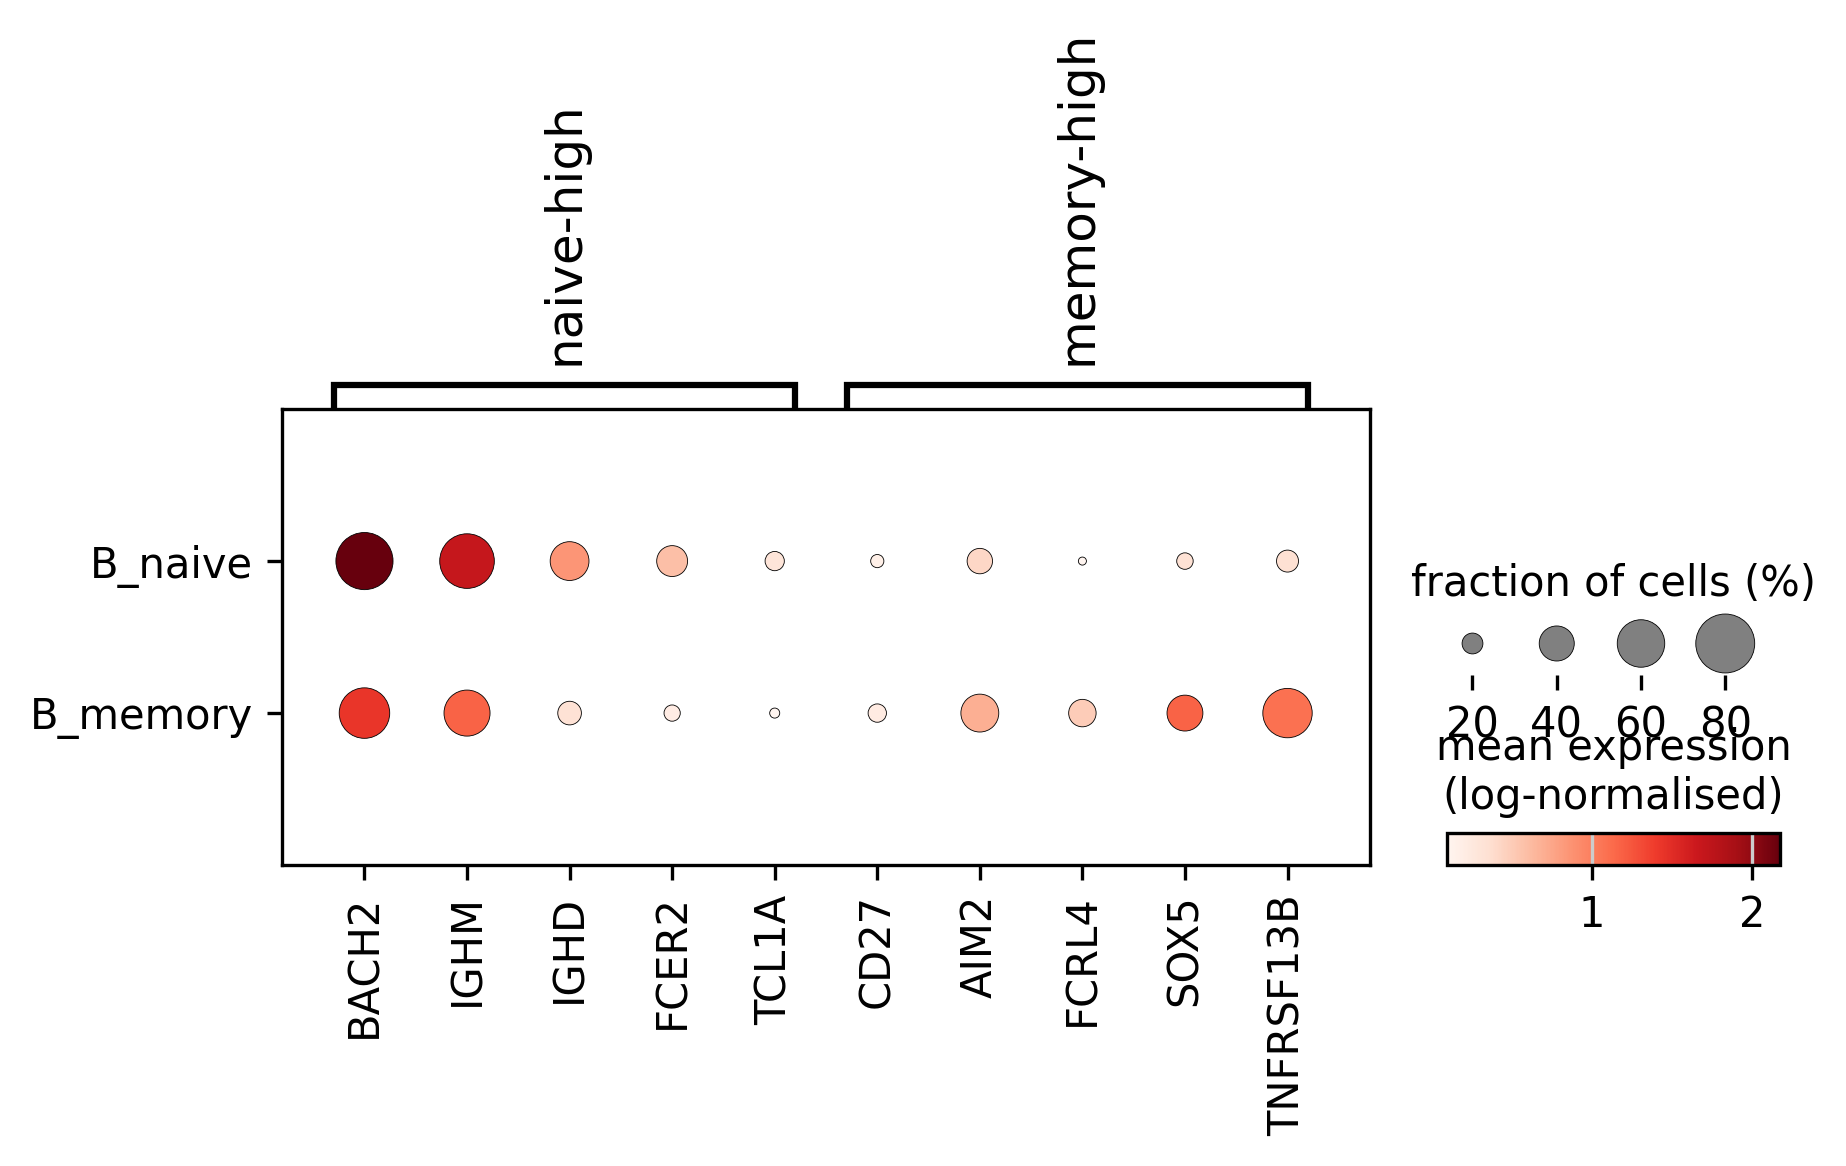

In [ ]:
# Do the published B_naive / B_memory annotations match canonical markers? 
NAIVE_MARKERS = ["BACH2", "IGHM", "IGHD", "FCER2", "TCL1A"]
MEMORY_MARKERS = ["CD27", "AIM2", "FCRL4", "SOX5", "TNFRSF13B"]
MARKERS = NAIVE_MARKERS + MEMORY_MARKERS

_full = sc.read_h5ad("/home/nathanl/Data/slidetags/tonsil_fullgenes.h5ad")
assert _full.obs_names.equals(adata.obs_names)
_mask = adata.obs["cell_type"].isin(B_PAIR).values
b_markers = _full[_mask, MARKERS].copy()
b_markers.obs["cell_type"] = pd.Categorical(adata.obs["cell_type"][_mask].astype(str), categories=B_PAIR, ordered=True)
del _full

sc.pl.dotplot(
    b_markers,
    var_names=MARKERS,
    groupby="cell_type",
    figsize=(6.4, 2.0),
    var_group_positions=[(0, len(NAIVE_MARKERS) - 1), (len(NAIVE_MARKERS), len(MARKERS) - 1)],
    var_group_labels=["naive-high", "memory-high"],
    colorbar_title="mean expression\n(log-normalised)",
    size_title="fraction of cells (%)",
    show=False,
)
save(f"tonsil_{PANEL}_bcell_canonical_markers")

annotation-derived reference markers (full genes): 168


,method,n_DE,on_target,off_target,recall,precision,ARI,F1
0,BANKSY (lambda 0.2),30,8,22,0.048,0.267,0.009,0.081
1,SimVI,50,20,30,0.119,0.400,0.049,0.183
2,scVI,166,79,87,0.470,0.476,0.089,0.473
3,scANVI,210,155,55,0.923,0.738,0.715,0.820
4,scVIVA,174,150,24,0.893,0.862,0.792,0.877
5,scVIVA (unlabeled),74,50,24,0.298,0.676,0.136,0.413


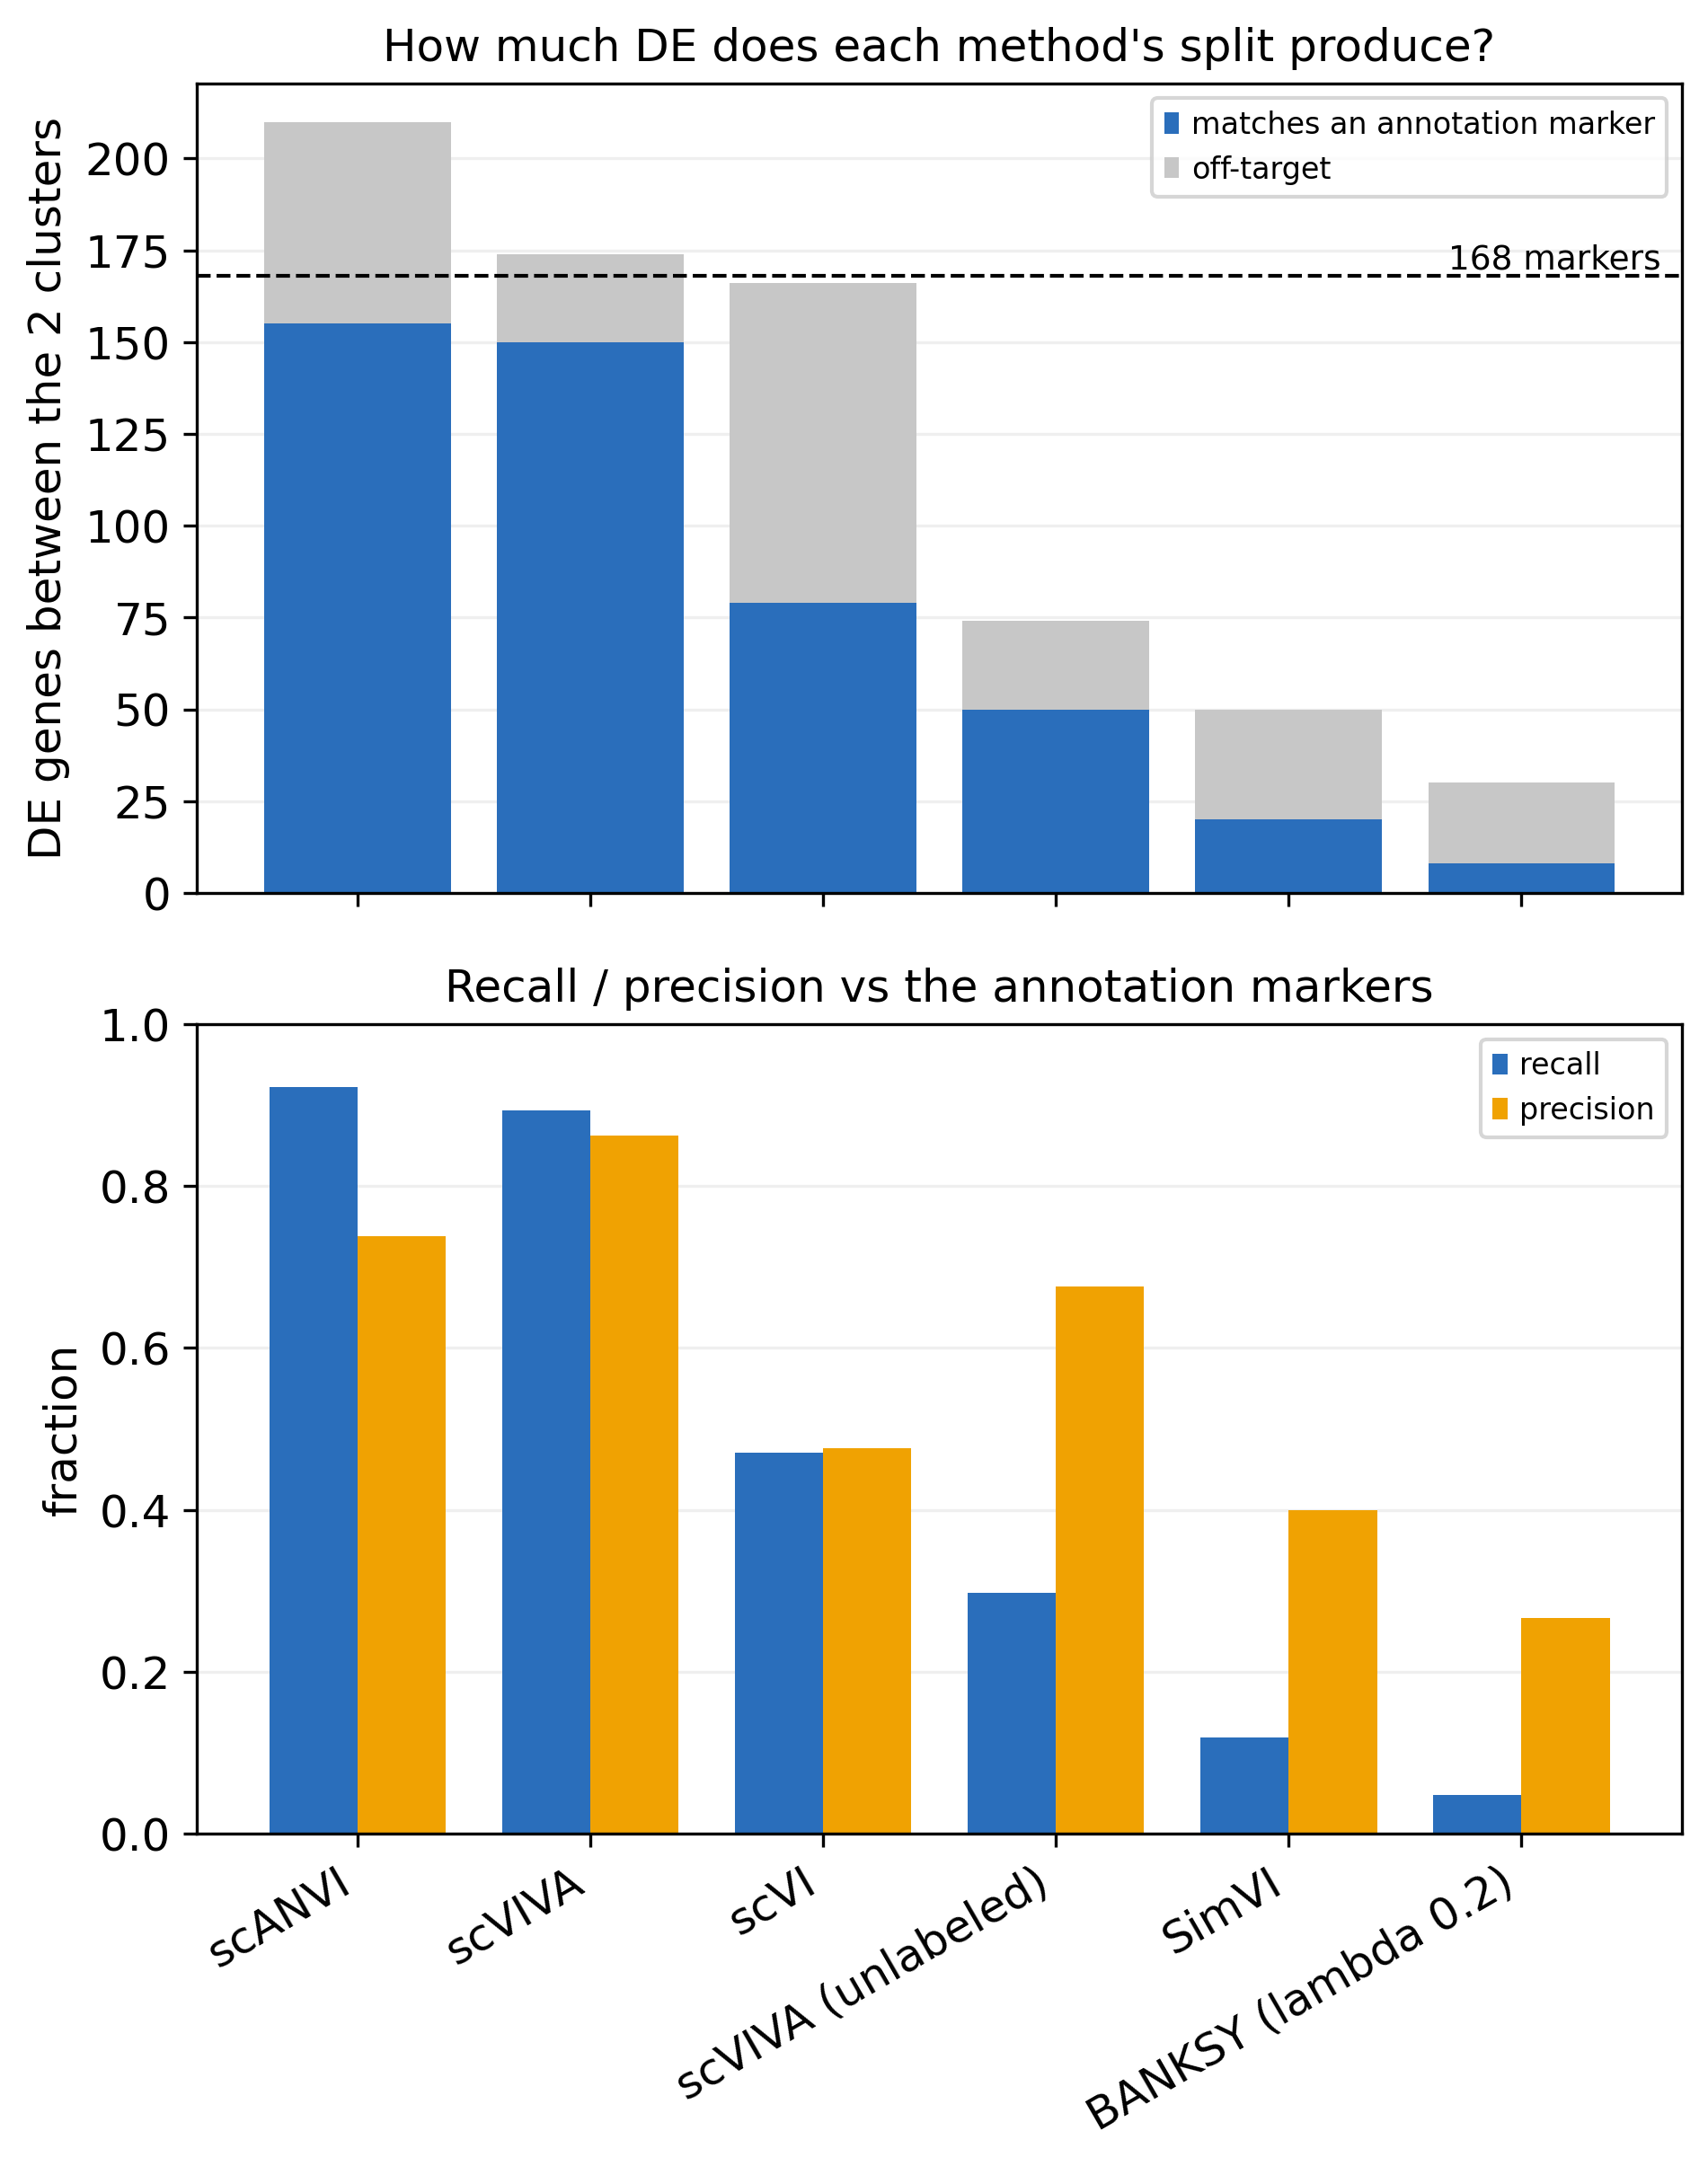

In [7]:
# Definitions (all DE: Wilcoxon, B_memory vs B_naive, on the full-gene log-normalised expression;
# a gene is "DE" if BH-adjusted p < 0.05 and |log2 fold change| > 1):
#   REF   = genes DE between the ANNOTATED B_memory and B_naive cells   -> the reference markers
#   FOUND = genes DE between a method's two blind KMeans(k=2) clusters, each cluster matched to
#           B_memory / B_naive by Hungarian assignment
#   recall    = |FOUND ∩ REF| / |REF|    fraction of the reference markers the method's split recovers
#   precision = |FOUND ∩ REF| / |FOUND|  fraction of the split's DE genes that are reference markers
#   F1        = harmonic mean of recall and precision
# "on_target" = |FOUND ∩ REF|, "off_target" = |FOUND| - on_target. Matching is by gene name only:
# the direction of the fold change is not compared. REF comes from the annotations, not from any
# embedding, so recall is not circular; off-target genes may still be real biology the annotation
# does not capture, so precision is the softer of the two numbers.
_full = sc.read_h5ad("/home/nathanl/Data/slidetags/tonsil_fullgenes.h5ad")
assert _full.obs_names.equals(adata.obs_names)

_mask = adata.obs["cell_type"].isin(B_PAIR).values
truth_b = adata.obs["cell_type"][_mask].astype(str).values
fb = _full[_mask].copy()
fb.obs["cell_type"] = pd.Categorical(truth_b, categories=B_PAIR)
del _full
for _k in full_embeddings.values():
    fb.obsm[_k] = adata.obsm[_k][_mask]


def _sig_set(ad_, groupby, group, reference):
    sc.tl.rank_genes_groups(ad_, groupby=groupby, groups=[group], reference=reference, method="wilcoxon")
    d = sc.get.rank_genes_groups_df(ad_, group=group)
    return set(d[(d["pvals_adj"] < 0.05) & (d["logfoldchanges"].abs() > 1)]["names"])


REF_MARKERS = _sig_set(fb, "cell_type", "B_memory", "B_naive")
print(f"annotation-derived reference markers (full genes): {len(REF_MARKERS)}")

rows = []
for label, key in full_embeddings.items():
    cl = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(fb.obsm[key])
    cm = pd.crosstab(truth_b, cl)
    r, c = linear_sum_assignment(-cm.values)
    mapping = {cm.columns[cj]: cm.index[ri] for ri, cj in zip(r, c)}
    fb.obs["cl"] = pd.Categorical([mapping[v] for v in cl], categories=B_PAIR)

    found = _sig_set(fb, "cl", "B_memory", "B_naive")
    on = len(found & REF_MARKERS)
    rows.append(
        {
            "method": label,
            "n_DE": len(found),
            "on_target": on,
            "off_target": len(found) - on,
            "recall": on / len(REF_MARKERS),
            "precision": on / len(found) if found else 0.0,
            "ARI": adjusted_rand_score(truth_b, cl),
        }
    )

recovery = pd.DataFrame(rows)
recovery["F1"] = (2 * recovery.recall * recovery.precision / (recovery.recall + recovery.precision)).fillna(0)
recovery.to_csv(os.path.join(FIGURES_FOLDER, f"tonsil_{PANEL}_bcell_de_recall_precision.csv"), index=False)
display(recovery.round(3))

_o = recovery.sort_values("n_DE", ascending=False)
_x = np.arange(len(_o))
fig, axes = plt.subplots(2, 1, figsize=(6.5, 8.2), sharex=True)  # stacked; both panels share the method order

ax = axes[0]
ax.bar(_x, _o["on_target"], color="#2a6ebb", label="matches an annotation marker")
ax.bar(_x, _o["off_target"], bottom=_o["on_target"], color="#c7c7c7", label="off-target")
ax.axhline(len(REF_MARKERS), ls="--", c="k", lw=1)
ax.text(len(_o) - 0.4, len(REF_MARKERS), f" {len(REF_MARKERS)} markers", va="bottom", ha="right", fontsize=9)
ax.set_xticks(_x)
ax.set_ylabel("DE genes between the 2 clusters")
ax.set_title("How much DE does each method's split produce?")
ax.legend(fontsize=8)

ax = axes[1]
_w = 0.38
ax.bar(_x - _w / 2, _o["recall"], _w, color="#2a6ebb", label="recall")
ax.bar(_x + _w / 2, _o["precision"], _w, color="#f0a202", label="precision")
ax.set_xticks(_x)
ax.set_xticklabels(_o["method"], rotation=30, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("fraction")
ax.set_title("Recall / precision vs the annotation markers")
ax.legend(fontsize=8)
for ax in axes:  # scanpy's figure params draw a full grid over the bars; keep light horizontal lines behind them
    ax.grid(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
plt.tight_layout()
save(f"tonsil_{PANEL}_bcell_de_recall_precision")

## 3. Plasma cells: germinal center vs mantle zone

In [8]:
PLASMA_REGIONS = ["germinal_center", "mantle_zone"]
_pm = ((adata.obs["cell_type"] == "plasma") & (adata.obs["region"].isin(PLASMA_REGIONS))).values
truth_p = adata.obs["region"][_pm].astype(str).values

p = adata[_pm].copy()
p.obs["region"] = pd.Categorical(truth_p, categories=PLASMA_REGIONS)

# the same cells with all genes (normalize_total(1e4) + log1p), for the marker expression
_full = sc.read_h5ad("/home/nathanl/Data/slidetags/tonsil_fullgenes.h5ad")
assert _full.obs_names.equals(adata.obs_names)
fp = _full[_pm].copy()
fp.obs["region"] = pd.Categorical(truth_p, categories=PLASMA_REGIONS)
del _full
print(f"plasma cells: n={p.n_obs}  GC={(truth_p == 'germinal_center').sum()}  mantle={(truth_p == 'mantle_zone').sum()}")

plasma cells: n=236  GC=187  mantle=49


### Plasma marker expression on the scVIVA UMAP

UMAP recomputed explicitly on the supervised scVIVA embedding (same neighbour/UMAP settings as
above). `vmax="p99"` clips the top 1% so a few high cells don't flatten the colour scale. Genes are
read from the full-gene object `fp` (CD38 is also a var name, which would collide in `.obs`).

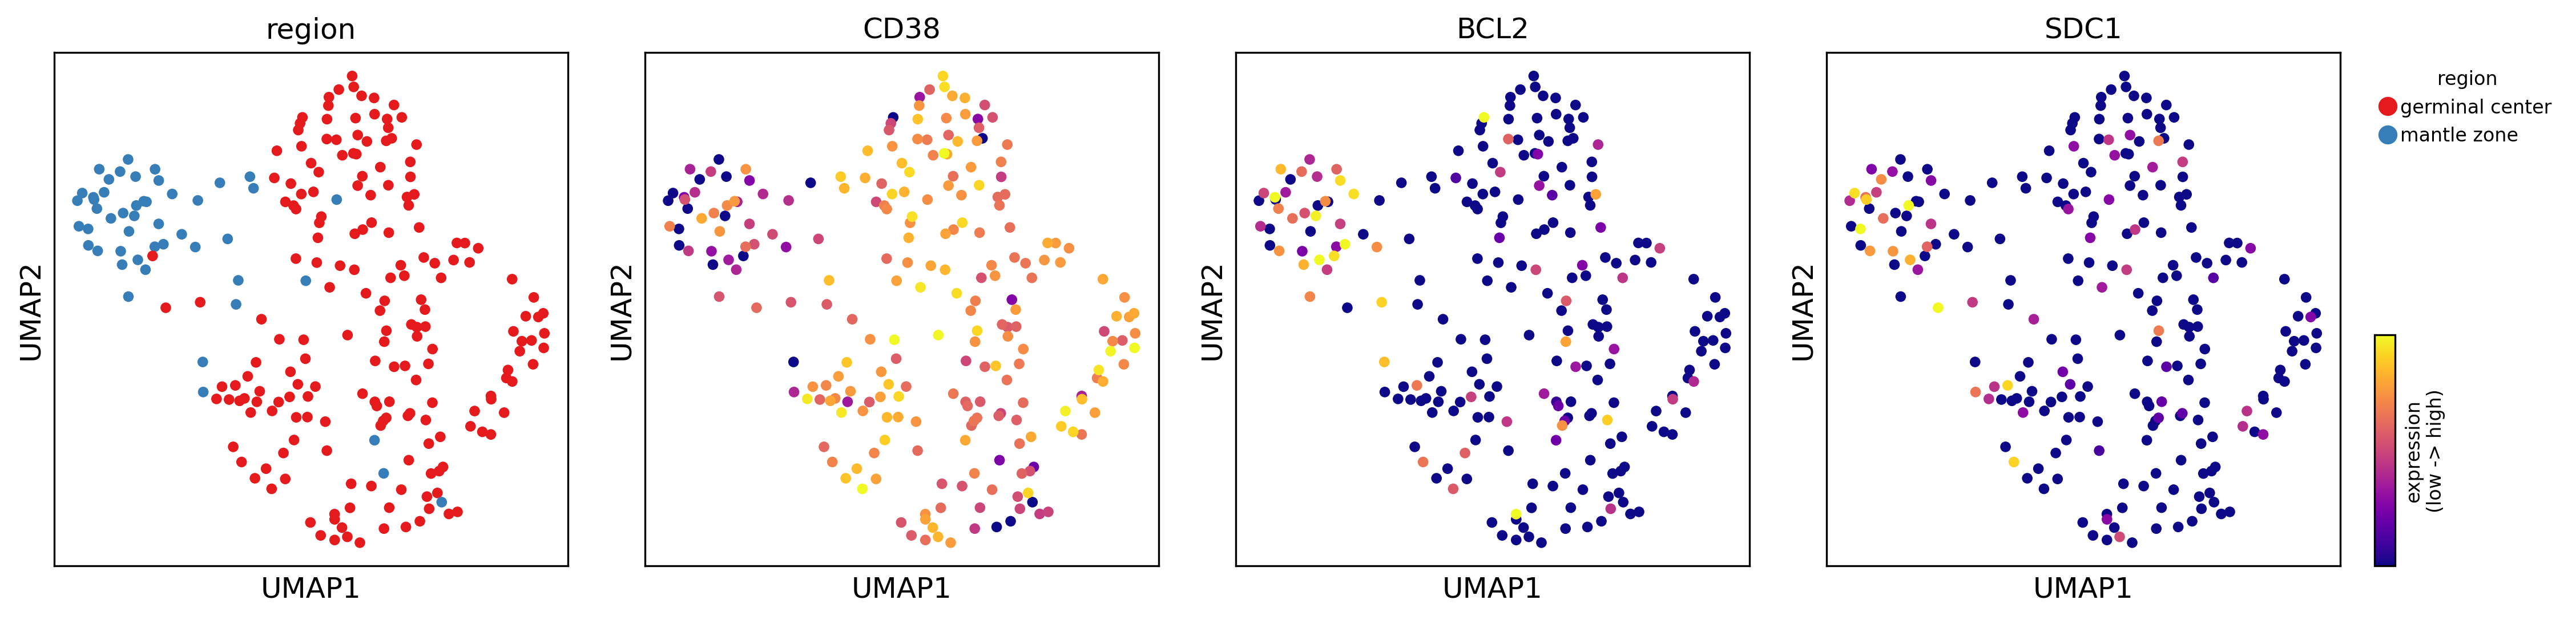

In [9]:
SCVIVA_KEY = full_embeddings["scVIVA"]

layer = "min_max_scaled"

p.obsm["_e"] = p.obsm[SCVIVA_KEY]
sc.pp.neighbors(p, use_rep="_e", n_neighbors=15)
sc.tl.umap(p, min_dist=0.3, random_state=0)
fp.obsm["X_umap"] = p.obsm["X_umap"]

# Min-max per gene across the PLASMA cells only (the 236 cells in this plot), on fp.X =
# normalize_total(1e4) + log1p -- i.e. depth-corrected, which matters here because GC plasma cells
# are sequenced ~2x deeper than mantle ones. 0 / 1 = lowest / highest plasma cell for that gene.
from sklearn.preprocessing import MinMaxScaler

_x = fp.X.toarray() if hasattr(fp.X, "toarray") else fp.X
fp.layers["min_max_scaled"] = MinMaxScaler().fit_transform(_x)

# UMAP_MARKERS = ["CD38", "TNFRSF17", "PRDM15"]
UMAP_MARKERS = ["CD38", "BCL2", "SDC1"]

# Fixed-size panels so this row and the baseline row below line up when stacked: every UMAP panel is
# PANEL_IN x PANEL_IN inches with the same gaps and left offset; legends / colorbars go in the right margin
# instead of shrinking a panel.
from matplotlib.lines import Line2D

PANEL_IN, GAP_IN, LEFT_IN, RIGHT_IN, TOP_IN, BOTTOM_IN = 3.0, 0.45, 0.45, 1.6, 0.45, 0.4
REGION_COLORS_PLASMA = {"germinal_center": "#e41a1c", "mantle_zone": "#377eb8"}


def fixed_axes_row(n):
    w = LEFT_IN + n * PANEL_IN + (n - 1) * GAP_IN + RIGHT_IN
    h = TOP_IN + PANEL_IN + BOTTOM_IN
    fig = plt.figure(figsize=(w, h))
    axes = [fig.add_axes([(LEFT_IN + j * (PANEL_IN + GAP_IN)) / w, BOTTOM_IN / h, PANEL_IN / w, PANEL_IN / h])
            for j in range(n)]
    return fig, axes, w, h


def region_legend(fig, w, h):
    handles = [Line2D([], [], marker="o", ls="", color=c, ms=7, label=r.replace("_", " "))
               for r, c in REGION_COLORS_PLASMA.items()]
    fig.legend(handles=handles, title="region", fontsize=8, title_fontsize=8, frameon=False, loc="upper left",
               bbox_to_anchor=((w - RIGHT_IN + 0.15) / w, (BOTTOM_IN + PANEL_IN) / h))


fig, axes, _w, _h = fixed_axes_row(1 + len(UMAP_MARKERS))
sc.pl.umap(
    fp,
    color="region",
    ax=axes[0],
    show=False,
    frameon=True,
    size=80,
    palette=list(REGION_COLORS_PLASMA.values()),
    title="region",
    legend_loc=None,
)
for ax, g in zip(axes[1:], UMAP_MARKERS):
    sc.pl.umap(
        fp,
        color=g,
        ax=ax,
        show=False,
        frameon=True,
        size=80,
        cmap="plasma",
        vmax="p99",
        title=g,
        layer=layer,
        colorbar_loc=None,
    )
for ax in axes:
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.grid(False)
region_legend(fig, _w, _h)
# one shared colorbar: each gene is min-max scaled over the plasma cells and its colour clipped at its 99th pct
_cax = fig.add_axes([(_w - RIGHT_IN + 0.2) / _w, BOTTOM_IN / _h, 0.12 / _w, 0.45 * PANEL_IN / _h])
_cb = fig.colorbar(axes[-1].collections[0], cax=_cax, ticks=[])
_cb.set_label("expression\n(low -> high)", fontsize=8)

save(f"tonsil_{PANEL}_plasma_markers_umap")

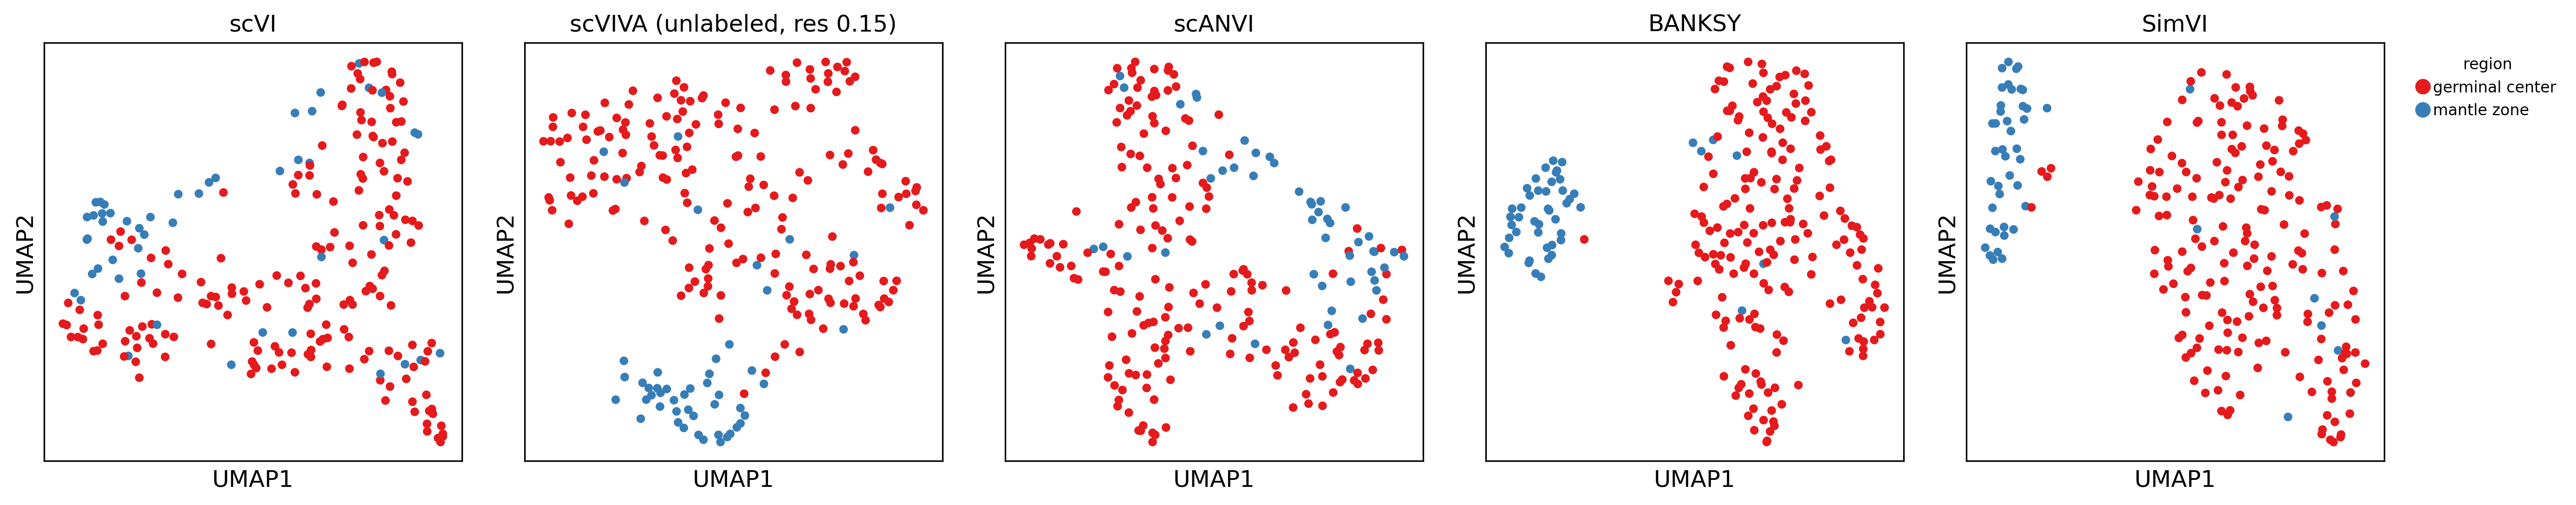

In [10]:
# Plasma cells on the other models' embeddings, coloured by region (same neighbour/UMAP settings as
# above). Each UMAP is stored under its own obsm key so p.obsm["X_umap"] (the scVIVA UMAP used by the
# marker plot) is left untouched.
BASELINE_UMAPS = {
    "scVI": full_embeddings["scVI"],
    # this notebook's unlabeled model: pseudo-labels = Leiden res 0.15 on scVI (silhouette rule)
    "scVIVA (unlabeled, res 0.15)": full_embeddings["scVIVA (unlabeled)"],
    "scANVI": full_embeddings["scANVI"],
    "BANKSY (lambda 0.2)": full_embeddings["BANKSY (lambda 0.2)"],
    "SimVI": full_embeddings["SimVI"],
}

fig, axes, _w, _h = fixed_axes_row(len(BASELINE_UMAPS))  # same panel size as the marker row (cell above)
for j, (ax, (label, key)) in enumerate(zip(axes, BASELINE_UMAPS.items())):
    _tmp = p.copy()
    _tmp.obsm["_e"] = _tmp.obsm[key]
    sc.pp.neighbors(_tmp, use_rep="_e", n_neighbors=15)
    sc.tl.umap(_tmp, min_dist=0.3, random_state=0)
    p.obsm[f"X_umap_{label}"] = _tmp.obsm["X_umap"]
    sc.pl.embedding(
        p,
        basis=f"X_umap_{label}",
        color="region",
        ax=ax,
        show=False,
        frameon=True,
        size=80,
        palette=list(REGION_COLORS_PLASMA.values()),
        title=label.replace(" (lambda 0.2)", ""),
        legend_loc=None,
    )
    ax.set_xlabel("UMAP1")  # scanpy would name the axes after the obsm key
    ax.set_ylabel("UMAP2")
    ax.grid(False)
del _tmp
region_legend(fig, _w, _h)

save(f"tonsil_{PANEL}_plasma_umap_region_baselines")

scVIVA KMeans(k=2)  scVIVA cluster: GC-matched  scVIVA cluster: MZ-matched
region                                                                    
germinal_center                            181                           6
mantle_zone                                  8                          41
dot_group
other cells                   5516
plasma (all)                   262
scVIVA cluster: GC-matched     189
scVIVA cluster: MZ-matched      47
Name: count, dtype: int64


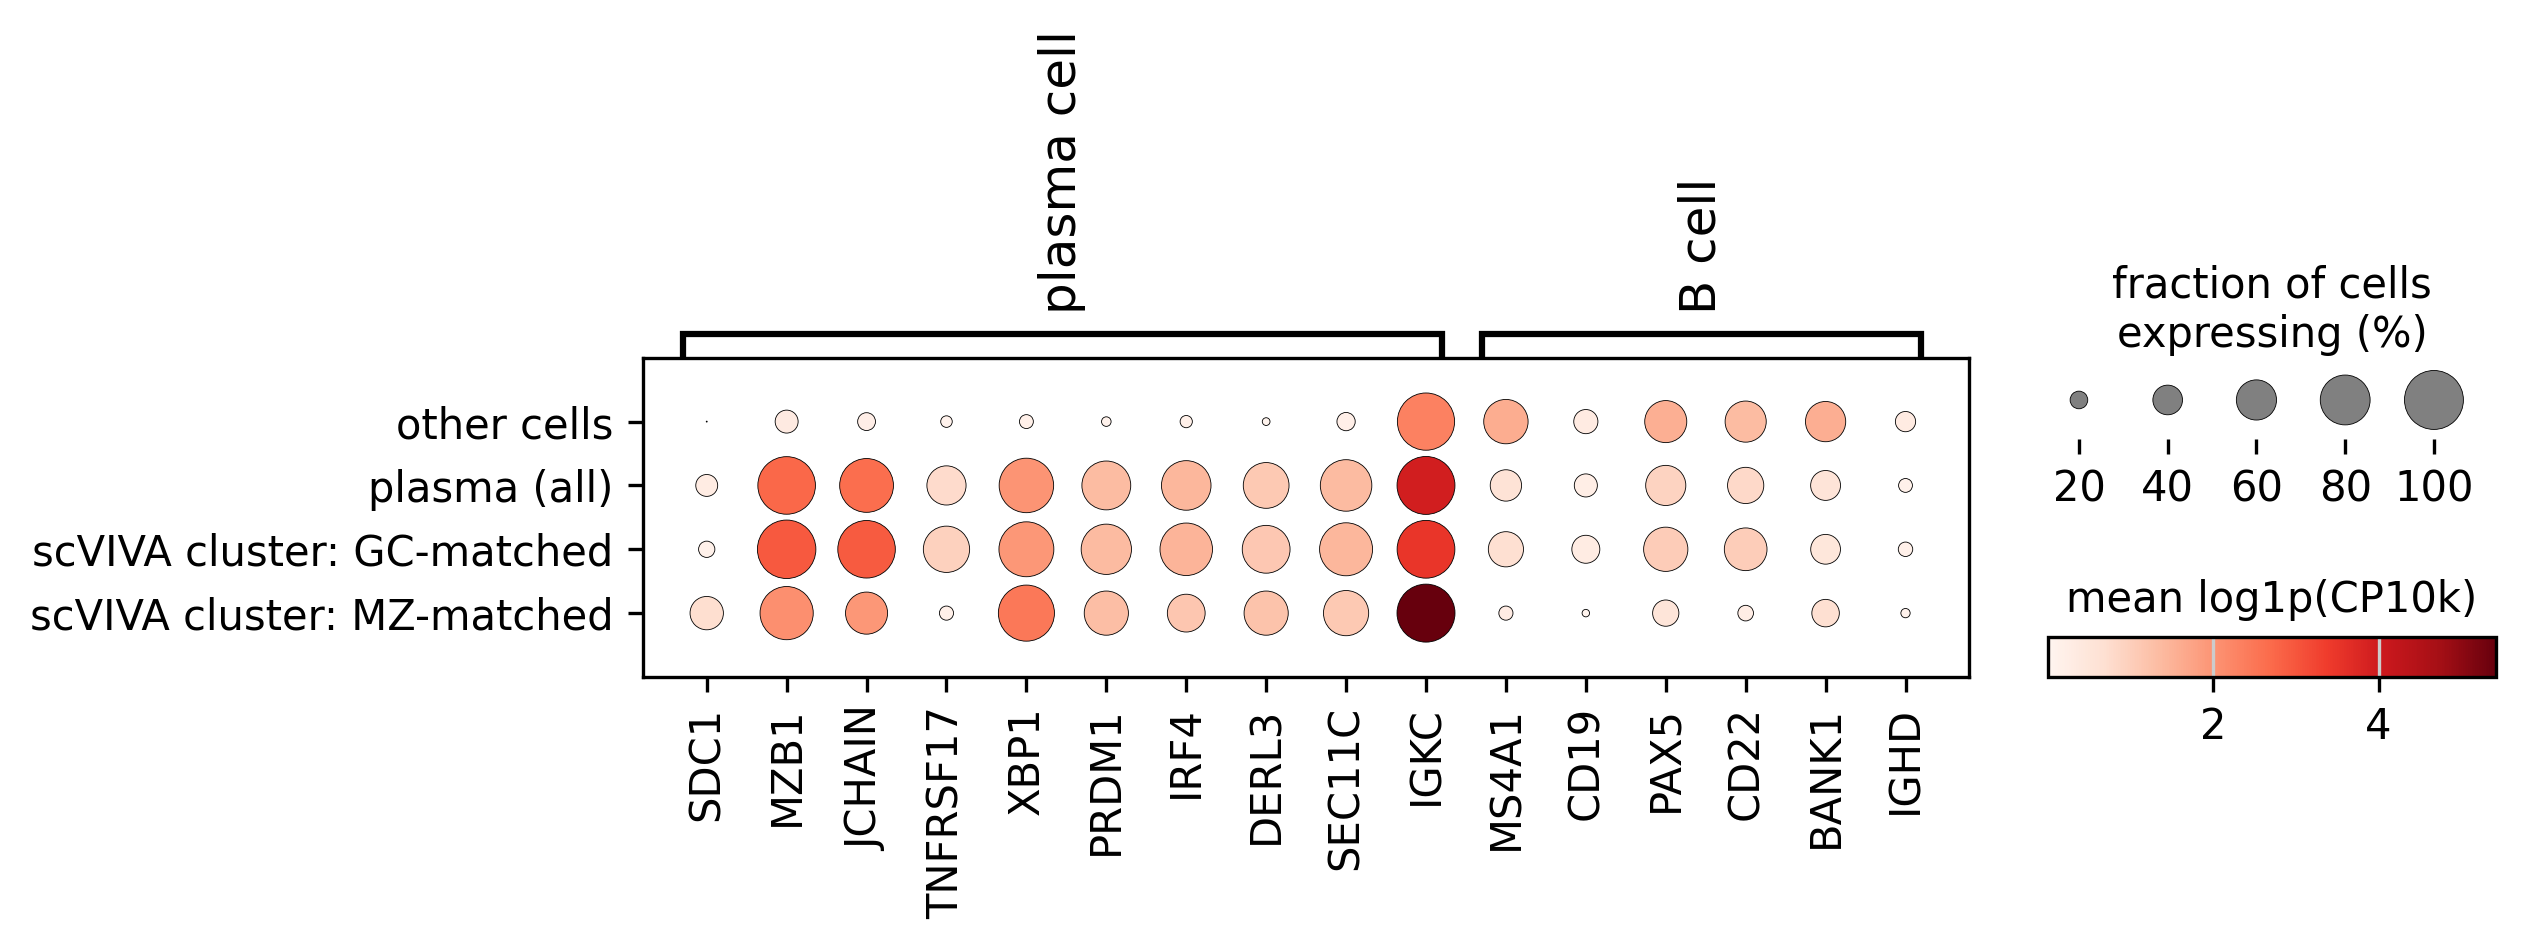

In [11]:
# Plasma-cell identity check on depth-normalised counts (all 23,563 genes: normalize_total(1e4) + log1p
# of the raw counts). Rows: all non-plasma cells, all annotated plasma cells, and scVIVA's two blind
# KMeans(k=2) clusters of the GC + mantle-zone plasma cells (each named after the region it matches by
# Hungarian assignment). Real plasma cells should be high on the plasma-cell markers and low on the
# B-cell markers. Cells appear in two rows (plasma + their scVIVA cluster): the rows are a display
# grouping, built by stacking two copies of the plasma cells.
from scipy.optimize import linear_sum_assignment as _lsa

DOT_PC_MARKERS = ["SDC1", "MZB1", "JCHAIN", "TNFRSF17", "XBP1", "PRDM1", "IRF4", "DERL3", "SEC11C", "IGKC"]
DOT_B_MARKERS = ["MS4A1", "CD19", "PAX5", "CD22", "BANK1", "IGHD"]
_PLASMA_REGIONS = ["germinal_center", "mantle_zone"]

_full = sc.read_h5ad("/home/nathanl/Data/slidetags/tonsil_fullgenes.h5ad")
assert _full.obs_names.equals(adata.obs_names)
_full.X = _full.layers["counts"].copy()
sc.pp.normalize_total(_full, target_sum=1e4)
sc.pp.log1p(_full)
_norm = _full[:, DOT_PC_MARKERS + DOT_B_MARKERS].copy()
del _full

_is_plasma = (adata.obs["cell_type"] == "plasma").values
_pm2 = _is_plasma & adata.obs["region"].isin(_PLASMA_REGIONS).values
_reg = adata.obs["region"][_pm2].astype(str).values
_cl = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(adata.obsm[full_embeddings["scVIVA"]][_pm2])
_cm = pd.crosstab(_reg, _cl)
_r, _c = _lsa(-_cm.values)
_name = {_cm.columns[j]: _cm.index[i] for i, j in zip(_r, _c)}
_short = {"germinal_center": "GC", "mantle_zone": "MZ"}
_cl_lab = np.array([f"scVIVA cluster: {_short[_name[v]]}-matched" for v in _cl])
print(pd.crosstab(pd.Series(_reg, name="region"), pd.Series(_cl_lab, name="scVIVA KMeans(k=2)")))

ROWS = ["other cells", "plasma (all)", "scVIVA cluster: GC-matched", "scVIVA cluster: MZ-matched"]
_a = _norm.copy()
_a.obs["dot_group"] = np.where(_is_plasma, "plasma (all)", "other cells")
_b = _norm[_pm2].copy()
_b.obs["dot_group"] = _cl_lab
_dot = sc.concat([_a, _b], index_unique="-")
_dot.obs["dot_group"] = pd.Categorical(_dot.obs["dot_group"], categories=ROWS)
print(_dot.obs["dot_group"].value_counts().reindex(ROWS))

dp = sc.pl.dotplot(
    _dot,
    var_names={"plasma cell": DOT_PC_MARKERS, "B cell": DOT_B_MARKERS},
    groupby="dot_group",
    cmap="Reds",
    return_fig=True,
)
dp.legend(width=2.0, colorbar_title="mean log1p(CP10k)", size_title="fraction of cells\nexpressing (%)")  # default is too narrow
dp.make_figure()
save(f"tonsil_{PANEL}_plasma_markers_dotplot")